# Patch–template distance distributions

For each template in a catalog dictionary, crop every associated matching patch
from the window spectrograms and measure

$$d = \sqrt{\frac{\|x - \Pi_V x\|_F^2}{H W}}$$

where $x$ is the patch of shape $(H, W)$ and $V$ is the template subspace (rank-1
or PCA atom). The numerator is residual energy after a least-squares fit
(`patch_template_distance`); dividing by $H W$ yields **residual energy per
pixel**, so $d$ is the RMS residual amplitude per pixel.

The last section calibrates the acceptance gate used by MP and by template
rebuilds, which works on the scale-free **unexplained energy fraction**

$$r = \frac{\|x - \Pi_V x\|_F^2}{\|x\|_F^2} \in [0, 1],
\qquad \text{accept} \iff r \le \tau,$$

so that a single `max_relative_distance` $= \tau$ can be picked from data.

Set `DICTIONARY_ID = None` to use the latest dictionary in the catalog.


In [1]:
%matplotlib inline

import sys
from contextlib import closing
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

REPO = Path("/home/yfreund/projects/gplrev3-webserver")
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from database import catalog
from analysis.dict_learning.code.core import Matching, Template
from analysis.dict_learning.code.core import patch_template_distance
from analysis.dict_learning.code.io import load_windows_from_paths
from analysis.dict_learning.code.learn.extend_dictionary import load_dictionary_from_catalog
from analysis.dict_learning.code.learn.seed_from_gpl import mean_center

LIBRARY_ROOT = Path("/home/yfreund/whale_processing")
DB_PATH = LIBRARY_ROOT / "result/dict_learning_catalog.sqlite"

# None → latest dictionary in the catalog
DICTIONARY_ID: int | None = 122

# Histogram layout for per-template panels
HIST_COLS = 4

# Candidate max_relative_distance thresholds to evaluate in the last section.
TAU_GRID = (0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)

## Load dictionary, matchings, and windows

In [2]:
with closing(catalog.connect(DB_PATH, read_only=True)) as conn:
    if DICTIONARY_ID is None:
        row = conn.execute(
            "SELECT dictionary_id, name, parent_dictionary_id, created_at "
            "FROM dictionaries ORDER BY dictionary_id DESC LIMIT 1"
        ).fetchone()
        dictionary_id = int(row["dictionary_id"])
        dict_meta = dict(row)
    else:
        dictionary_id = int(DICTIONARY_ID)
        dict_meta = catalog.get_dictionary(conn, dictionary_id)
        if dict_meta is None:
            raise ValueError(f"dictionary_id={dictionary_id} not found")

    dictionary = load_dictionary_from_catalog(conn, dictionary_id)

    matching_rows = conn.execute(
        """
        SELECT m.window_id, m.t_start, m.amplitude, t.template_id, t.width
        FROM matchings m
        JOIN templates t ON t.template_pk = m.template_pk
        WHERE m.dictionary_id = ?
        ORDER BY t.template_id, m.window_id, m.t_start
        """,
        (dictionary_id,),
    ).fetchall()

    window_rows = catalog.list_dictionary_windows(conn, dictionary_id)

paths = [r["npy_path"] for r in window_rows if r.get("npy_path")]
if not paths:
    raise RuntimeError(f"dictionary {dictionary_id} has no window npy paths")

windows = load_windows_from_paths(paths)
stack = {w.window_id: mean_center(w.data) for w in windows}

matchings = [
    Matching(
        template_id=int(r["template_id"]),
        window_id=str(r["window_id"]),
        t_start=int(r["t_start"]),
        amplitude=float(r["amplitude"] if r["amplitude"] is not None else 1.0),
    )
    for r in matching_rows
]

display(
    Markdown(
        f"**Dictionary {dictionary_id}** — `{dict_meta['name']}`  \n"
        f"parent={dict_meta.get('parent_dictionary_id')}  "
        f"created={dict_meta.get('created_at')}  \n"
        f"templates={len(dictionary)}  matchings={len(matchings)}  "
        f"windows={len(stack)}"
    )
)

**Dictionary 115** — `reviewed_rebuild_reviewed_rebuild_reviewed_rebuild_leidata_wav1_extend_from111_w20_a5_pinned`  
parent=114  created=2026-07-31T22:34:03.349865+00:00  
templates=14  matchings=391  windows=20

## Compute $\sqrt{\text{residual energy per pixel}}$ per patch

In [3]:
@dataclass
class PatchDistance:
    template_id: int
    window_id: str
    t_start: int
    width: int
    residual_energy: float
    patch_energy: float
    explained_energy: float
    amplitude: float

    @property
    def distance(self) -> float:
        """RMS residual per pixel: sqrt(residual_energy / (H*W))."""
        return float(np.sqrt(max(self.residual_energy, 0.0)))

    @property
    def relative_distance(self) -> float:
        """RMS residual relative to RMS patch amplitude: sqrt of `r`."""
        denom = float(np.sqrt(max(self.patch_energy, 0.0)))
        return self.distance / denom if denom > 0.0 else np.nan

    @property
    def r(self) -> float:
        """Unexplained energy fraction — exactly what the gate thresholds."""
        if self.patch_energy <= 0.0:
            return np.nan
        return float(self.residual_energy / self.patch_energy)


def crop_patch(stack: dict[str, np.ndarray], matching: Matching, width: int) -> np.ndarray | None:
    arr = stack.get(matching.window_id)
    if arr is None:
        return None
    t0 = int(matching.t_start)
    t1 = t0 + int(width)
    if t0 < 0 or t1 > arr.shape[1]:
        return None
    return np.asarray(arr[:, t0:t1], dtype=np.float64)


records: list[PatchDistance] = []
skipped = 0
for matching in matchings:
    template = dictionary.templates.get(int(matching.template_id))
    if template is None:
        skipped += 1
        continue
    width = int(template.width)
    patch = crop_patch(stack, matching, width)
    if patch is None or patch.shape != tuple(template.basis.shape[-2:]):
        skipped += 1
        continue
    residual, patch_e, explained = patch_template_distance(
        patch, template, return_parts=True
    )
    # Normalize to per-pixel energies: divide by H×W.
    n_pix = float(patch.shape[0] * patch.shape[1])
    records.append(
        PatchDistance(
            template_id=int(matching.template_id),
            window_id=matching.window_id,
            t_start=int(matching.t_start),
            width=width,
            residual_energy=float(residual) / n_pix,
            patch_energy=float(patch_e) / n_pix,
            explained_energy=float(explained) / n_pix,
            amplitude=float(matching.amplitude or 0.0),
        )
    )

template_ids = sorted(dictionary.order)
by_template: dict[int, list[PatchDistance]] = {tid: [] for tid in template_ids}
for rec in records:
    by_template.setdefault(rec.template_id, []).append(rec)

print(f"computed {len(records)} patch distances ({skipped} skipped)")
for tid in template_ids:
    n = len(by_template.get(tid, []))
    w = dictionary.templates[tid].width
    print(f"  template {tid:2d}: {n:4d} patches  width={w}")

computed 391 patch distances (0 skipped)
  template  0:   28 patches  width=21
  template  1:   16 patches  width=21
  template  3:   24 patches  width=20
  template  4:   12 patches  width=14
  template  6:   31 patches  width=21
  template  7:    6 patches  width=21
  template  8:   38 patches  width=14
  template  9:   90 patches  width=13
  template 10:   53 patches  width=13
  template 11:    4 patches  width=16
  template 12:   77 patches  width=12
  template 13:    6 patches  width=14
  template 14:    4 patches  width=20
  template 15:    2 patches  width=24


## Summary statistics

In [4]:
def summarize_template(tid: int, rows: list[PatchDistance]) -> dict:
    if not rows:
        return {
            "template_id": tid,
            "n": 0,
            "width": dictionary.templates[tid].width,
        }
    d = np.asarray([r.distance for r in rows], dtype=np.float64)
    rel = np.asarray([r.relative_distance for r in rows], dtype=np.float64)
    return {
        "template_id": tid,
        "n": len(rows),
        "width": dictionary.templates[tid].width,
        "mean": float(np.mean(d)),
        "std": float(np.std(d)),
        "median": float(np.median(d)),
        "p25": float(np.percentile(d, 25)),
        "p75": float(np.percentile(d, 75)),
        "max": float(np.max(d)),
        "rel_median": float(np.nanmedian(rel)),
    }


summary_rows = [summarize_template(tid, by_template.get(tid, [])) for tid in template_ids]
header = (
    f"{'tid':>3}  {'n':>4}  {'W':>3}  {'mean':>8}  {'std':>8}  {'median':>8}  "
    f"{'p25':>8}  {'p75':>8}  {'max':>8}  {'rel_med':>8}"
)
print(header)
print("-" * len(header))
for s in summary_rows:
    if s["n"] == 0:
        print(f"{s['template_id']:3d}  {s['n']:4d}  {s['width']:3d}  (no patches)")
        continue
    print(
        f"{s['template_id']:3d}  {s['n']:4d}  {s['width']:3d}  "
        f"{s['mean']:8.3f}  {s['std']:8.3f}  {s['median']:8.3f}  "
        f"{s['p25']:8.3f}  {s['p75']:8.3f}  {s['max']:8.3f}  {s['rel_median']:8.3f}"
    )

tid     n    W      mean       std    median       p25       p75       max   rel_med
------------------------------------------------------------------------------------
  0    28   21     3.623     1.256     3.260     2.564     4.718     6.956     0.750
  1    16   21     3.602     0.750     3.421     3.061     3.942     5.406     0.884
  3    24   20     5.112     1.191     4.966     4.331     6.193     7.082     0.812
  4    12   14     2.860     0.821     2.953     2.635     3.091     4.783     0.758
  6    31   21     1.575     0.766     1.466     0.970     2.055     3.328     0.969
  7     6   21     3.139     0.462     3.019     2.944     3.547     3.733     0.583
  8    38   14     2.015     0.661     1.977     1.589     2.556     3.328     0.754
  9    90   13     2.756     1.358     2.841     1.370     3.581     5.795     0.935
 10    53   13     2.662     1.578     2.385     1.297     3.792     7.116     0.985
 11     4   16     2.085     0.998     1.761     1.582     2.264 

## Per-template histograms

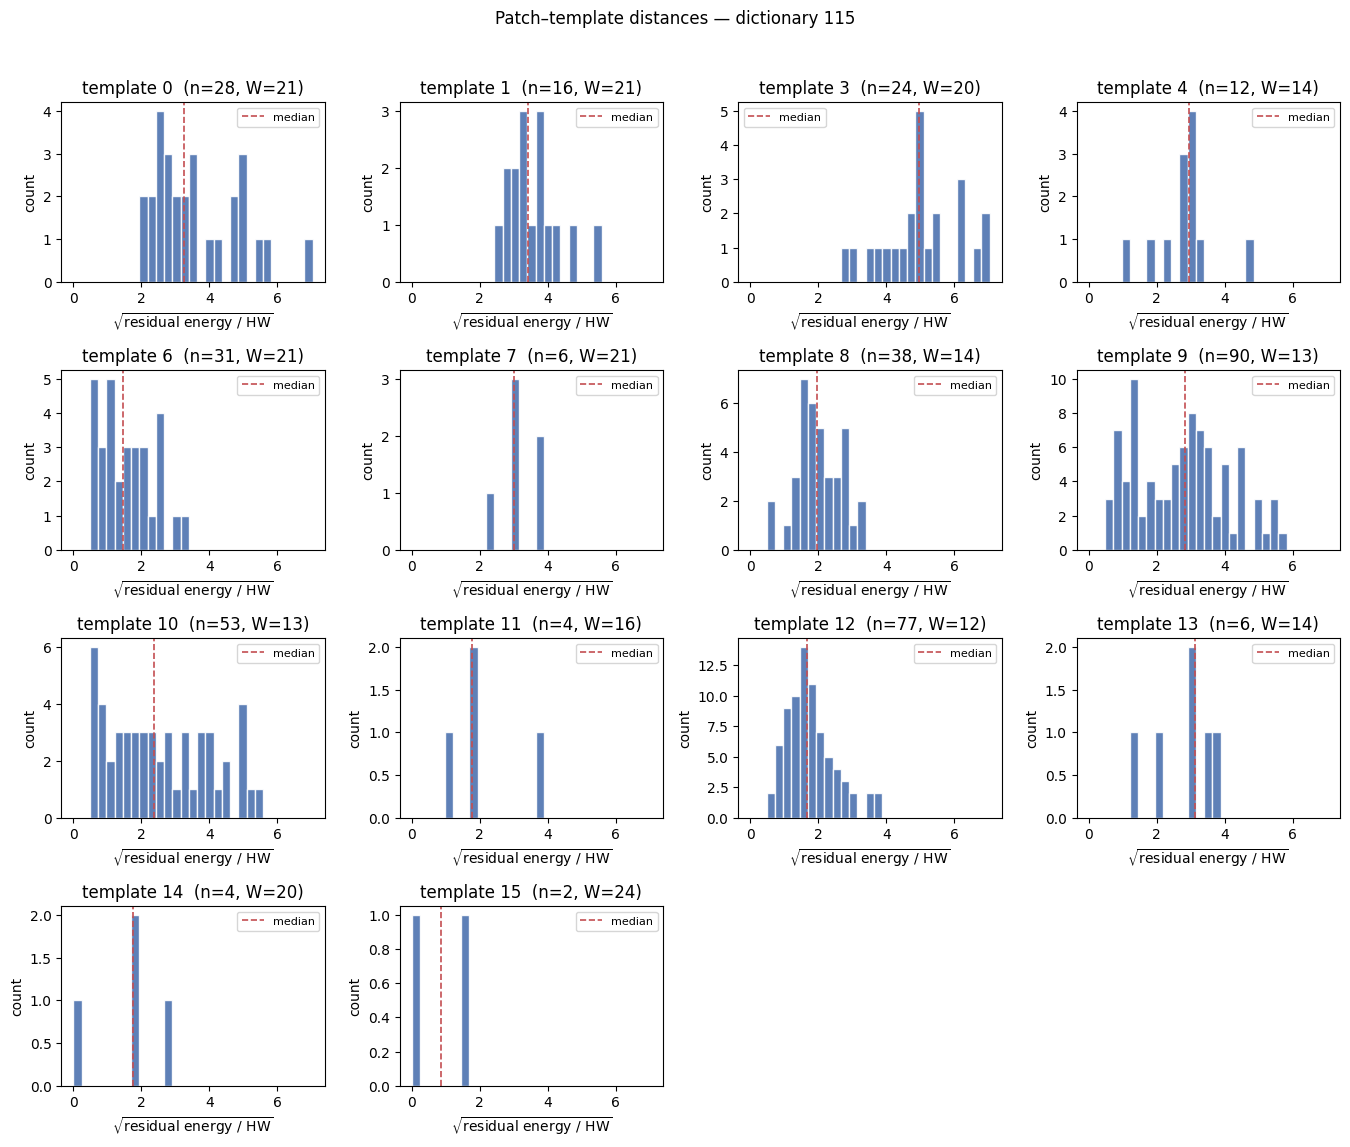

In [5]:
active = [tid for tid in template_ids if by_template.get(tid)]
if not active:
    raise RuntimeError("No patch distances to plot")

n = len(active)
cols = min(HIST_COLS, n)
rows_n = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(3.4 * cols, 2.8 * rows_n), squeeze=False)

all_d = np.concatenate([np.asarray([r.distance for r in by_template[tid]]) for tid in active])
bins = np.linspace(0.0, float(np.percentile(all_d, 99.5)), 30)

for idx, tid in enumerate(active):
    ax = axes.flat[idx]
    d = np.asarray([r.distance for r in by_template[tid]], dtype=np.float64)
    ax.hist(d, bins=bins, color="#4c72b0", edgecolor="white", alpha=0.9)
    ax.axvline(float(np.median(d)), color="#c44e52", ls="--", lw=1.2, label="median")
    ax.set_title(f"template {tid}  (n={len(d)}, W={dictionary.templates[tid].width})")
    ax.set_xlabel(r"$\sqrt{\mathrm{residual\ energy\ /\ HW}}$")
    ax.set_ylabel("count")
    ax.legend(fontsize=8)

for j in range(n, rows_n * cols):
    axes.flat[j].axis("off")

fig.suptitle(f"Patch–template distances — dictionary {dictionary_id}", y=1.02)
fig.tight_layout()
plt.show()

## Box plot and empirical CDFs

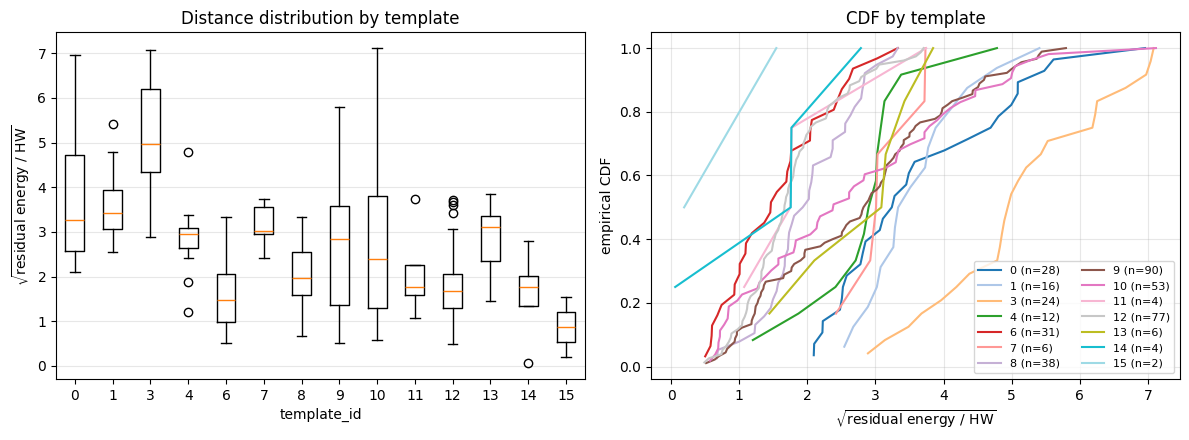

In [6]:
labels = [str(tid) for tid in active]
data = [np.asarray([r.distance for r in by_template[tid]], dtype=np.float64) for tid in active]

fig, (ax_box, ax_cdf) = plt.subplots(1, 2, figsize=(12, 4.5))

ax_box.boxplot(data, tick_labels=labels, showfliers=True)
ax_box.set_xlabel("template_id")
ax_box.set_ylabel(r"$\sqrt{\mathrm{residual\ energy\ /\ HW}}$")
ax_box.set_title("Distance distribution by template")
ax_box.grid(axis="y", alpha=0.3)

cmap = plt.cm.tab20(np.linspace(0, 1, max(len(active), 1)))
for color, tid, d in zip(cmap, active, data):
    xs = np.sort(d)
    ys = np.arange(1, xs.size + 1) / xs.size
    ax_cdf.plot(xs, ys, label=f"{tid} (n={xs.size})", color=color, lw=1.5)
ax_cdf.set_xlabel(r"$\sqrt{\mathrm{residual\ energy\ /\ HW}}$")
ax_cdf.set_ylabel("empirical CDF")
ax_cdf.set_title("CDF by template")
ax_cdf.grid(alpha=0.3)
ax_cdf.legend(fontsize=8, ncol=2)

fig.tight_layout()
plt.show()

## Outliers (top 5 per template by distance)

In [7]:
for tid in active:
    rows = sorted(by_template[tid], key=lambda r: r.distance, reverse=True)[:5]
    print(f"\ntemplate {tid} — largest distances:")
    for r in rows:
        win = r.window_id.split("_")[-4] if "_w" in r.window_id else r.window_id
        print(
            f"  d={r.distance:8.3f}  rel={r.relative_distance:6.3f}  "
            f"t={r.t_start:4d}  amp={r.amplitude:7.3f}  {win}"
        )


template 0 — largest distances:
  d=   6.956  rel= 0.998  t=  41  amp=  3.831  003345.x
  d=   5.613  rel= 1.000  t= 453  amp=  0.020  003345.x
  d=   5.477  rel= 1.000  t= 268  amp=  0.019  003345.x
  d=   5.089  rel= 0.998  t= 123  amp=  2.807  003345.x
  d=   5.087  rel= 1.000  t= 362  amp=  0.011  003345.x

template 1 — largest distances:
  d=   5.406  rel= 0.900  t=  76  amp=  1.030  003345.x
  d=   4.781  rel= 0.846  t= 452  amp=  1.025  003345.x
  d=   4.346  rel= 0.781  t=  84  amp=  1.142  003345.x
  d=   4.118  rel= 0.935  t= 512  amp=  0.431  003345.x
  d=   3.883  rel= 0.869  t= 533  amp=  1.105  003345.x

template 3 — largest distances:
  d=   7.082  rel= 0.579  t= 271  amp=  2.206  003345.x
  d=   7.037  rel= 0.922  t= 520  amp=  0.652  003345.x
  d=   6.972  rel= 0.605  t= 432  amp=  2.031  003345.x
  d=   6.670  rel= 0.932  t= 326  amp=  0.572  003345.x
  d=   6.253  rel= 0.989  t= 282  amp=  0.205  003345.x

template 4 — largest distances:
  d=   4.783  rel= 0.830  t=

## Calibrating `max_relative_distance`

Histogram of the unexplained energy fraction $r$ per template, with candidate
thresholds $\tau$ overlaid. A patch is accepted (by MP, and as input to the
template rebuild) when $r \le \tau$, so each vertical line marks the patches
that would survive to its left.

In [ ]:
r_by_template = {
    tid: np.asarray([rec.r for rec in by_template[tid]], dtype=np.float64)
    for tid in active
}

n = len(active)
cols = min(HIST_COLS, n)
rows_n = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(3.4 * cols, 2.8 * rows_n), squeeze=False)
r_bins = np.linspace(0.0, 1.0, 41)
tau_colors = plt.cm.viridis(np.linspace(0.15, 0.9, len(TAU_GRID)))

for idx, tid in enumerate(active):
    ax = axes.flat[idx]
    values = r_by_template[tid]
    values = values[np.isfinite(values)]
    ax.hist(values, bins=r_bins, color="#55a868", edgecolor="white", alpha=0.9)
    for color, tau in zip(tau_colors, TAU_GRID):
        ax.axvline(tau, color=color, ls=":", lw=1.0)
    ax.axvline(float(np.median(values)), color="#c44e52", ls="--", lw=1.4, label="median")
    ax.set_xlim(0.0, 1.0)
    ax.set_title(f"template {tid}  (n={values.size})")
    ax.set_xlabel(r"$r$ = unexplained energy fraction")
    ax.set_ylabel("count")
    ax.legend(fontsize=8)

for j in range(n, rows_n * cols):
    axes.flat[j].axis("off")

fig.suptitle(
    f"Unexplained energy fraction $r$ — dictionary {dictionary_id} "
    f"(dotted lines: candidate $\\tau$)",
    y=1.02,
)
fig.tight_layout()
plt.show()

### Kept fraction per template for each candidate $\tau$

The worst-served template sets the practical floor: a $\tau$ that leaves any
atom with fewer patches than its `n_components` will fall back to `min_keep`
during rebuild, and can starve that atom during MP.

On dictionary 122 the whitened background keeps $r$ high even for good
matches — roughly 60% of accepted patches sit above $r = 0.8$ — so a useful
$\tau$ there is at the top of the range, trimming the tail rather than
selecting a "close" minority. Read the numbers below before picking one.

In [ ]:
header = f"{'tid':>3}  {'n':>4}  " + "  ".join(f"tau={tau:<4.2f}" for tau in TAU_GRID)
print(header)
print("-" * len(header))
for tid in active:
    values = r_by_template[tid]
    values = values[np.isfinite(values)]
    cells = "  ".join(
        f"{np.mean(values <= tau):8.2f}" for tau in TAU_GRID
    )
    print(f"{tid:3d}  {values.size:4d}  {cells}")

all_r = np.concatenate([r_by_template[tid] for tid in active])
all_r = all_r[np.isfinite(all_r)]
print("-" * len(header))
print(
    f"{'all':>3}  {all_r.size:4d}  "
    + "  ".join(f"{np.mean(all_r <= tau):8.2f}" for tau in TAU_GRID)
)
print(
    "\nworst-template kept fraction: "
    + "  ".join(
        f"tau={tau:.2f}: "
        f"{min(float(np.mean(r_by_template[t][np.isfinite(r_by_template[t])] <= tau)) for t in active):.2f}"
        for tau in TAU_GRID
    )
)